In [1]:
from sklearn import svm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import RobustScaler
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report
import joblib
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
import seaborn as sns
import numpy as np
from scipy.signal import find_peaks
import matplotlib.pyplot as plt
from scipy.ndimage import uniform_filter1d
import pandas as pd
from scipy import signal
from scipy.ndimage.interpolation import shift
from sklearn.model_selection import KFold
from sklearn.metrics import accuracy_score
from sklearn import tree
from sklearn import ensemble
from functools import reduce
import os
#regex module
import re
pattern = r'[0-9]'

C:\Users\wwo20\AppData\Local\Temp\ipykernel_14704\3152813614.py:19: DeprecationWarning: Please import `shift` from the `scipy.ndimage` namespace; the `scipy.ndimage.interpolation` namespace is deprecated and will be removed in SciPy 2.0.0.
  from scipy.ndimage.interpolation import shift


In [2]:
def Compile(filenames,distance=200,height=5.5,prominence=1,plot=True,shot_length=2.5):
    n= len(filenames)
    for i in range(0,n):
        if i == 0: #AllfPitch, AllfRoll,AllfYaw   DfPitch, DfRoll,DfYaw
            AllfGyroX, AllfGyroY, AllfGyroZ,AllfAccelX, AllfAccelY, AllfAccelZ, AllfAccelTime,AllfPitch, AllfRoll,AllfYaw,Allname,Allshot,Allshots_made   = segment(filenames[i],prominence,distance,height,100,shot_length,plot)
        else:
            DfGyroX, DfGyroY, DfGyroZ,DfAccelX, DfAccelY, DfAccelZ,DfGyroTime,DfPitch, DfRoll,DfYaw,Dname,Dshot,Dshots_made = segment(filenames[i],prominence,distance,height,100,shot_length,plot)
            AllfGyroX = np.hstack((AllfGyroX, DfGyroX))
            AllfGyroY = np.hstack((AllfGyroY, DfGyroY))
            AllfGyroZ = np.hstack((AllfGyroZ, DfGyroZ))
            AllfAccelX = np.hstack((AllfAccelX, DfAccelX))
            AllfAccelY = np.hstack((AllfAccelY, DfAccelY))
            AllfAccelZ = np.hstack((AllfAccelZ, DfAccelZ))
            AllfPitch = np.hstack((AllfPitch, DfPitch))
            AllfRoll = np.hstack((AllfRoll, DfRoll))
            AllfYaw = np.hstack((AllfYaw, DfYaw))
            Allname= np.hstack((Allname, Dname))
            Allshot= np.hstack((Allshot, Dshot))
            Allshots_made= np.hstack((Allshots_made, Dshots_made))

    return AllfGyroX, AllfGyroY, AllfGyroZ, AllfAccelX, AllfAccelY, AllfAccelZ,AllfPitch, AllfRoll,AllfYaw,Allname,Allshot,Allshots_made


def segment(Filename,prominence, distance, height,frequency,shot_length,plot=False):
    """
    Segments the accelerometer data into separate shots based on gyro data peaks.

    Parameters:
    bData (str): The path to the CSV file containing the accelerometer data.

    Returns:
    SignalX_Accel (ndarray): Array containing the X-axis acceleration data for each shot.
    SignalY_Accel (ndarray): Array containing the Y-axis acceleration data for each shot.
    SignalZ_Accel (ndarray): Array containing the Z-axis acceleration data for each shot.
    SignalTime (ndarray): Array containing the time domain data for each shot.
    """
    # Function code goes here
#Convert CSV file to pandas then numpy array
    # bData = np.genfromtxt(bData, delimiter=',', skip_header=1)
    global pattern
    file= pd.read_csv(Filename)
    # Backhand data set
    bData = file.to_numpy()
    # scaler = StandardScaler()
    # bData = scaler.fit_transform(bData)
    bPacketNumber = np.arange(0,len(bData[:, 0]))
    f= frequency # because the frequency used is 128Hz
    bTimedomain = bPacketNumber / f   # because the frequency used is 128Hz
    shot= Filename.split('Watch Sensor/')[1].split('_')[0]
    shots_made=  Filename.split('Watch Sensor')[1].split('/Motion')[0].split(shot+'_')[1].split('_')[0]
    name= Filename.split('Watch Sensor')[1].split('/Motion')[0].split(shot+'_')[1].split('_')[1]
    #some motion csv were named like shottype_shotsmade_name2.. name3, if it was the same multiple of shot for the same shot type
    #So take awya the numbers
    name= re.sub(pattern, '', name)
    windowSize = 10
    bGyroX = bData[:, 4]
    bGyroY = bData[:, 5]
    bGyroZ = bData[:, 6]
    bAccelerationX = bData[:, 1]
    bAccelerationY = bData[:, 2]
    bAccelerationZ = bData[:, 3]
    bAccelMean = np.sqrt((bAccelerationX**2) + (bAccelerationY**2) + (bAccelerationZ**2))  # absolute magnitude accel
    bAccelMeanMovav = np.convolve(bAccelMean, np.ones(windowSize), 'valid') / windowSize  # moving average backhand
    bGyroMean = np.sqrt((bGyroX**2) + (bGyroY**2) + (bGyroZ**2))  # absolute magnitude gyro
    bMeanMovav = np.convolve(bGyroMean, np.ones(windowSize), 'valid') / windowSize  # moving average backhand
    bPitch= bData[:, 10]
    bRoll= bData[:, 11]
    bYaw= bData[:, 12]
    print(f'{Filename}')
    bpks, _ = find_peaks(bMeanMovav, prominence=prominence, distance=distance, height=height)  # peak distance of 2s and min peak height of .600
    #check if acceleration magnitude is above 2, from data this should be true for even the weakest shots. It seperates non shot actions
    bpks= bpks[bAccelMeanMovav[bpks]>1]
    if plot:
        plt.figure()
        plt.ylabel('Gyro magnitude (�/s)')
        plt.plot(np.arange(0, len(bMeanMovav))/f, bMeanMovav)
        plt.scatter(bpks/f,bMeanMovav[bpks],c="r")
        plt.xlabel('Time (s)')  # x-axis label
      # y-axis label
    shot_len = shot_length # seconds
  
    size = int(shot_len*f)
    # Saving each shot into separate column of one big array
    # shot length is assumed to be 5s in length
    SignalTime = np.zeros((size, len(bpks)))
    SignalX_Accel = np.zeros((size, len(bpks)))
    SignalY_Accel = np.zeros((size, len(bpks)))
    SignalZ_Accel = np.zeros((size, len(bpks)))
    SignalX_Gyro = np.zeros((size, len(bpks)))
    SignalY_Gyro = np.zeros((size, len(bpks)))
    SignalZ_Gyro = np.zeros((size, len(bpks)))
    Signal_pitch= np.zeros((size, len(bpks)))
    Signal_roll= np.zeros((size, len(bpks)))
    Signal_yaw= np.zeros((size, len(bpks)))
    print(SignalTime.shape)
    half_shot= int(size/2)
    for j in range(len(bpks)):
        timeIndex = bpks[j]  # select first time value of peak
        if j == 0:
            startSignal = 0
            endSignal = size
        elif j == len(bpks) - 1:
            startSignal = len(bTimedomain) - size
            endSignal = len(bTimedomain)
        else:
            startSignal = timeIndex - half_shot# subtract 2.5s worth of data points from peak to obtain time when shot begins
            endSignal = timeIndex + half_shot# add 2.5s worth of data points from peak to obtain end of signal
        SignalTime[:, j] = bTimedomain[startSignal:endSignal]  # 1 shot in time index to be saved in Signal matrix
        SignalX_Gyro[:, j] = bGyroX[startSignal:endSignal]
        SignalY_Gyro[:, j] = bGyroY[startSignal:endSignal]
        SignalZ_Gyro[:, j] = bGyroZ[startSignal:endSignal]
        SignalX_Accel[:, j] = bAccelerationX[startSignal:endSignal]
        SignalY_Accel[:, j] = bAccelerationY[startSignal:endSignal]
        SignalZ_Accel[:, j] = bAccelerationZ[startSignal:endSignal]
        Signal_pitch[:, j] = bPitch[startSignal:endSignal]
        Signal_roll[:, j] = bRoll[startSignal:endSignal]
        Signal_yaw[:, j] = bYaw[startSignal:endSignal]
        #normalise the yaw pitch and roll values by their starting value since we dont care about teh absolute
        #only the change in rotation
        Signal_pitch[:, j] = Signal_pitch[:, j] - Signal_pitch[0, j]
        Signal_roll[:, j] = Signal_roll[:, j] - Signal_roll[0, j]
        Signal_yaw[:, j] = Signal_yaw[:, j] - Signal_yaw[0, j]
    
    #convert to degrees
    Signal_pitch= np.degrees(Signal_pitch)
    Signal_roll= np.degrees(Signal_roll)
    Signal_yaw= np.degrees(Signal_yaw)

    # plt.figure()
    # fig, axs = plt.subplots()
    # fig2, axs2 = plt.subplots()
    # fig3, axs3 = plt.subplots()
    # axs.title.set_text('a_x')
    # axs2.title.set_text('a_y')
    # axs3.title.set_text('a_z')
    # for plotIdx in range(SignalX_Accel.shape[1]):
    #     axs.plot(SignalX_Accel[:, plotIdx], 'r')  # overlay all forehand shots onto 1 curve
    #     axs2.plot(SignalY_Accel[:, plotIdx], 'g')  # overlay all forehand shots onto 1 curve
    #     axs3.plot(SignalZ_Accel[:, plotIdx], 'b')  # overlay all forehand shots onto 1 curve
    # plt.xlabel('Time (s)')  # x-axis label
    # plt.ylabel('Acceleration (�/s)')  # y-axis label


    #Uncomment the following lines if you want to plot the data
    # plt.figure()
    # for plotIdx in range(SignalX_Accel.shape[1]):
    #     plt.plot(SignalX_Accel[:, plotIdx], 'r')  # overlay all forehand shots onto 1 curve
    #     plt.xlabel('Time (s)')  # x-axis label
    #     plt.ylabel('Acceleration (g)')  # y-axis label
    #     plt.title('X Acceleration in Time Domain')
    # plt.figure()
    # for plotIdx in range(SignalX_Accel.shape[1]):
    #     plt.plot(SignalY_Accel[:, plotIdx], 'g')  # overlay all forehand shots onto 1 curve
    #     plt.xlabel('Time (s)')  # x-axis label
    #     plt.ylabel('Acceleration (g)')  # y-axis label
    #     plt.title('Y Acceleration in Time Domain')
    # plt.figure()
    # for plotIdx in range(SignalX_Accel.shape[1]):
    #     plt.plot(SignalZ_Accel[:, plotIdx], 'b')  # overlay all forehand shots onto 1 curve
    #     plt.xlabel('Time (s)')  # x-axis label

    #     plt.ylabel('Acceleration (g)')  # y-axis label
    #     plt.title('Z Acceleration in Time Domain')
    # plt.show()
    return SignalX_Gyro,SignalY_Gyro,SignalZ_Gyro,SignalX_Accel, SignalY_Accel, SignalZ_Accel, SignalTime ,Signal_pitch,Signal_roll,Signal_yaw,[name]*len(bpks),shot,int(shots_made)

def feature_template(AllfGyroX, AllfGyroY, AllfGyroZ, AllfAccelX, AllfAccelY, AllfAccelZ,title, AllSignal_pitch, AllSignal_roll,AllSignal_yaw,shot):
    # Angular Velocities
    AllfGyro_av = np.mean(np.array([AllfGyroX, AllfGyroY, AllfGyroZ]), axis=0)

    # Racket linear speed
    R = 0.7445  # radius from shoulder to point of impact of ball
    Maxes = np.max(np.abs(AllfGyro_av), axis=0)
    Peaky = Maxes[1]
    Peakz = Maxes[2]
    omega = np.sqrt((Peaky * 0.0174533) ** 2 + (Peakz * 0.0174533) ** 2)
    LinSpeed = omega * R

    # Spin Rating
    maxiY = np.max(np.abs(AllfGyroY))
    maxY = np.max(maxiY)
    minY = np.min(maxiY)
    maxiZ = np.max(np.abs(AllfGyroZ))
    maxZ = np.max(maxiZ)
    minZ = np.min(maxiZ)
    if maxiY.size > 0 and maxiZ.size > 0:
        omega_high = np.sqrt(maxY ** 2 + maxZ ** 2)
        omega_low = np.sqrt(minY ** 2 + minZ ** 2)
        theta_high = omega_high * 0.12
        theta_low = omega_low * 0.12
    else:
        theta_high = 0
        theta_low = 0

    # Plotting
    # plt.figure()
    # plt.plot(AllfGyro_av[0, :], 'r', linewidth=1.5)
    # plt.plot(AllfGyro_av[1, :], 'g', linewidth=1.5)
    # plt.plot(AllfGyro_av[2, :], 'b', linewidth=1.5)
    # plt.legend(['\omega_x', '\omega_y', '\omega_z'])
    # plt.xlabel('Time (s)')  # x-axis label
    # plt.ylabel('Gyroscope (°/s)')  # y-axis label

    # Acceleration mag for Power Rating
    AllfAccel_av = np.mean(np.array([AllfAccelX, AllfAccelY, AllfAccelZ]), axis=0)
    MagAccel = np.sqrt(AllfAccelZ ** 2)  # magnitude of acceleration for all shots
    MagAccelPeaks = MagAccel[229:237, :]
    MagAccelmeans = np.mean(MagAccelPeaks, axis=0)
    if MagAccelmeans.size > 0:
        magA_low = np.min(MagAccelmeans[:], axis=0)
        magA_high = np.max(MagAccelmeans[:])
    else:
        magA_low = 0
        magA_high = 0

    # global eval('title[]')
    #unique values in title
    global players
    for i in players:
        Signal_pitch= AllSignal_pitch[:,title==i]
        if Signal_pitch.size > 0:
            fig2,ax2= plt.subplots(1,1)
            fig2.suptitle(f'Average {np.unique(shot)[0]} Rotations for '+ i)
            Signal_roll= AllSignal_roll[:,title==i]
            Signal_yaw= AllSignal_yaw[:,title==i]
            rotation_average= np.array([[np.average(Signal_pitch,axis=1)], [np.average(Signal_roll,axis=1)], [np.average(Signal_yaw,axis=1)]])
            pitch_smoothness= np.std(np.diff(Signal_pitch)).round(2)
            roll_smoothness= np.std(np.diff(Signal_roll)).round(2)
            yaw_smoothness= np.std(np.diff(Signal_yaw)).round(2)
            for j in range(rotation_average.shape[0]):
                ax2.plot(rotation_average[j,0,:]) 
                ax2.set_xlabel('Time (s)')
                ax2.set_ylabel('Rotation (�/s)')
            plt.legend([f'Pitch with smoothness {pitch_smoothness}', f'Roll with smoothness {roll_smoothness}', f'Yaw with smoothness {yaw_smoothness}'], loc='lower left')
            plt.show()
            Accelx= AllfAccelX[:,title==i]
            Accely= AllfAccelY[:,title==i]
            Accelz= AllfAccelZ[:,title==i]
            print(Accelx.shape)
            Accel=['x','y','z']
            fig,ax= plt.subplots(3,1,sharex=True)
            fig.suptitle(f'Average {np.unique(shot)[0]} Acceleration for '+ i)
            ax[2].set_xlabel('Time (s)')
            for j in range(3):
                ax[j].plot(np.average(eval(f'Accel{Accel[j]}'),axis=1))
                ax[j].set_ylabel('Acceleration (g) in ' + Accel[j])
            plt.show()
    return AllfGyro_av, AllfAccel_av, LinSpeed, theta_high, theta_low, magA_low, magA_high

def MaxMin(fGyroX, fGyroY, fGyroZ, fAccelX, fAccelY, fAccelZ):
    # Minimum
    gMin = np.array([np.min(fGyroX, axis=0), np.min(fGyroY, axis=0), np.min(fGyroZ, axis=0)]).T
    aMin = np.array([np.min(fAccelX, axis=0), np.min(fAccelY, axis=0), np.min(fAccelZ, axis=0)]).T

    # Maximum
    gMax = np.array([np.max(fGyroX, axis=0), np.max(fGyroY, axis=0), np.max(fGyroZ, axis=0)]).T
    aMax = np.array([np.max(fAccelX, axis=0), np.max(fAccelY, axis=0), np.max(fAccelZ, axis=0)]).T

    # Mean
    gMean = np.array([np.mean(fGyroX, axis=0), np.mean(fGyroY, axis=0), np.mean(fGyroZ, axis=0)]).T
    aMean = np.array([np.mean(fAccelX, axis=0), np.mean(fAccelY, axis=0), np.mean(fAccelZ, axis=0)]).T

    # Std
    gStd = np.array([np.std(fGyroX, axis=0), np.std(fGyroY, axis=0), np.std(fGyroZ, axis=0)]).T
    aStd = np.array([np.std(fAccelX, axis=0), np.std(fAccelY, axis=0), np.std(fAccelZ, axis=0)]).T

    # Under curve
    gArea = np.array([np.trapz(fGyroX, axis=0), np.trapz(fGyroY, axis=0), np.trapz(fGyroZ, axis=0)]).T
    aArea = np.array([np.trapz(fAccelX, axis=0), np.trapz(fAccelY, axis=0), np.trapz(fAccelZ, axis=0)]).T

    return aMax, aMin, aMean, aStd, aArea, gMax, gMin, gMean, gStd, gArea

def Cross_cor_template(SignalXG, SignalYG, SignalZG,SignalXA, SignalYA, SignalZA,freq, avgtemplate,length=2.5):
    # From analyssi we know that the templates of YA XG AND ZG are most consistent, so we will use them to align the data
    size= int(length*freq) # length s of data
    SignalGraph = np.linspace(0,size,size) # Shot in time index (starting at 0) to be used for plotting
    num= len(SignalXG[0,:] )# Number of shots
    print("pre alignment")    # Used for graph for progress report - can be otherwise commented out
    # plt.figure()
     # # Plotting for each signal axis
    # for axis in ['X', 'Y', 'Z']:
    #     plt.figure()
    #     plt.title(f'Gyro {axis} Pre-Alignment')
    #     for j in range(0, num, 1):
    #         plt.plot(SignalGraph, eval(f'Signal{axis}G[:,j]'), 'r')
    #         if j == 0:
    #             plt.legend([f'Gyro {axis}'], loc='upper right')
    #         else:
    #             pass

    #     plt.figure()
    #     plt.title(f'Accel {axis} Pre-Alignment')
    #     for j in range(0, num, 1):
    #         plt.plot(SignalGraph, eval(f'Signal{axis}A[:,j]'), 'r')
    #         if j == 0:
    #             plt.legend([f'Accel {axis}'], loc='upper right')
    #         else:
                # pass

    # for each
    global lag_values
    lag_values = np.zeros([num,6])
    for i in range(0,num,1):
        lag_values[i,0]=  np.argmax(signal.correlate(SignalXG[:,i], avgtemplate[:,0]))
        lag_values[i,1]=  np.argmax(signal.correlate(SignalYG[:,i], avgtemplate[:,1]))
        lag_values[i,2]=  np.argmax(signal.correlate(SignalZG[:,i], avgtemplate[:,2]))
        lag_values[i,3]=  np.argmax(signal.correlate(SignalXA[:,i], avgtemplate[:,3]))
        lag_values[i,4]=  np.argmax(signal.correlate(SignalYA[:,i], avgtemplate[:,4]))
        lag_values[i,5]=  np.argmax(signal.correlate(SignalZA[:,i], avgtemplate[:,5]))    

def confusion_and_accuracy(y_test, y_pred, labels,title):
    # Calculate accuracy
    accuracy = accuracy_score(y_test, y_pred)
    #%%
    # Generate confusion matrix
    confusion_mat = confusion_matrix(y_test, y_pred)

    # Create a heatmap of the confusion matrix
    plt.figure(figsize=(8, 6))
    sns.heatmap(confusion_mat, annot=True, cmap='Blues', fmt='d', xticklabels=labels, yticklabels=labels)
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    #
    # Calculate percentages for each class
    confusion_mat_percent = confusion_mat / confusion_mat.sum(axis=1)[:, np.newaxis]

    # Create a heatmap of the confusion matrix with percentages
    plt.figure(figsize=(8, 6))
    sns.heatmap(confusion_mat_percent, annot=True, cmap='Blues', fmt='.2%', xticklabels=labels, yticklabels=labels)
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.title('Confusion Matrix (Percentages)')

    plt.show()
    print("Accuracy is", accuracy*100, "%")
def cross_corr(SignalXG, SignalYG, SignalZG,SignalXA, SignalYA, SignalZA,freq):
    
    size= int(2.5*freq) # 2.5s of data
    SignalGraph = np.linspace(0,size,size) # Shot in time index (starting at 0) to be used for plotting
    num= len(SignalXG[0,:] )# Number of shots
    print("pre alignment")    # Used for graph for progress report - can be otherwise commented out
    # plt.figure()

    # # Plotting for each signal axis
    # for axis in ['X', 'Y', 'Z']:
    #     plt.figure()
    #     plt.title(f'Gyro {axis} Pre-Alignment')
    #     for j in range(0, num, 1):
    #         plt.plot(SignalGraph, eval(f'Signal{axis}G[:,j]'), 'r')
    #         if j == 0:
    #             plt.legend([f'Gyro {axis}'], loc='upper right')
    #         else:
    #             pass

    #     plt.figure()
    #     plt.title(f'Accel {axis} Pre-Alignment')
    #     for j in range(0, num, 1):
    #         plt.plot(SignalGraph, eval(f'Signal{axis}A[:,j]'), 'r')
    #         if j == 0:
    #             plt.legend([f'Accel {axis}'], loc='upper right')
    #         else:
                # pass

    
    # lag values could be from -size+1 (smallest overlap on LHS) to size-timestep (smallest overlap on RHS)
    lag_values = np.arange(-size+1, size, 1)
    m = SignalXG.shape # Shot Martrix Shape (data points x no. of shots)
    
    global lag
    # Pairs of signals are combined and the cross correlation is evalauted
    # The two signals are realigned and averaged
    # This iterative process keeps repeating until one template signal is left - therefore must start with power of 2 shots
    
    if num >= 64:
    
        path = np.array([32,16,8,4,2])
        avg_prop = np.zeros([32,size,6])
        avg_prop2 = np.zeros([16,size,6])
        avg_prop3 = np.zeros([8,size,6])
        avg_prop4 = np.zeros([4,size,6])
        avg_prop5 = np.zeros([2,size,6])

        for j in path:

            correlation = np.zeros([j,m[0]*2-1, 6])
            lag = np.zeros([j,6])
            max_crosscorr = np.zeros([j,6])

            for i in range(0,2*j,2):

                n = int(i/2)

                if j == 32:

                    correlation[n,:,0] = signal.correlate(SignalXG[:,i], SignalXG[:,i+1])
                    correlation[n,:,1] = signal.correlate(SignalYG[:,i], SignalYG[:,i+1])
                    correlation[n,:,2] = signal.correlate(SignalZG[:,i], SignalZG[:,i+1])
                    correlation[n,:,3] = signal.correlate(SignalXA[:,i], SignalXA[:,i+1])
                    correlation[n,:,4] = signal.correlate(SignalYA[:,i], SignalYA[:,i+1])
                    correlation[n,:,5] = signal.correlate(SignalZA[:,i], SignalZA[:,i+1])

                    max_crosscorr = np.argmax(correlation[n,:,:], axis=0)
                    lag[n,:] = lag_values[max_crosscorr]

                    SignalXG[:,i+1] = shift(SignalXG[:,i+1], -1*lag[n,0], cval=0)
                    SignalYG[:,i+1] = shift(SignalYG[:,i+1], -1*lag[n,1], cval=0)
                    SignalZG[:,i+1] = shift(SignalZG[:,i+1], -1*lag[n,2], cval=0)
                    SignalXA[:,i+1] = shift(SignalXA[:,i+1], -1*lag[n,3], cval=0)
                    SignalYA[:,i+1] = shift(SignalYA[:,i+1], -1*lag[n,4], cval=0)
                    SignalZA[:,i+1] = shift(SignalZA[:,i+1], -1*lag[n,5], cval=0)

                    avg_prop[n,:,0] = np.average(SignalXG[:,i:i+1], axis=1)
                    avg_prop[n,:,1] = np.average(SignalYG[:,i:i+1], axis=1)
                    avg_prop[n,:,2] = np.average(SignalZG[:,i:i+1], axis=1)
                    avg_prop[n,:,3] = np.average(SignalXA[:,i:i+1], axis=1)
                    avg_prop[n,:,4] = np.average(SignalYA[:,i:i+1], axis=1)
                    avg_prop[n,:,5] = np.average(SignalZA[:,i:i+1], axis=1)

                elif j == 16:

                    correlation[n,:,0] = signal.correlate(avg_prop[i,:,0], avg_prop[i+1,:,0])
                    correlation[n,:,1] = signal.correlate(avg_prop[i,:,1], avg_prop[i+1,:,1])
                    correlation[n,:,2] = signal.correlate(avg_prop[i,:,2], avg_prop[i+1,:,2])
                    correlation[n,:,3] = signal.correlate(avg_prop[i,:,3], avg_prop[i+1,:,3])
                    correlation[n,:,4] = signal.correlate(avg_prop[i,:,4], avg_prop[i+1,:,4])
                    correlation[n,:,5] = signal.correlate(avg_prop[i,:,5], avg_prop[i+1,:,5])

                    max_crosscorr = np.argmax(correlation[n,:,:], axis=0)
                    lag[n,:] = lag_values[max_crosscorr]

                    avg_prop[i+1,:,0] = shift(avg_prop[i+1,:,0], -1*lag[n,0], cval=0)
                    avg_prop[i+1,:,1] = shift(avg_prop[i+1,:,1], -1*lag[n,1], cval=0)
                    avg_prop[i+1,:,2] = shift(avg_prop[i+1,:,2], -1*lag[n,2], cval=0)
                    avg_prop[i+1,:,3] = shift(avg_prop[i+1,:,3], -1*lag[n,3], cval=0)
                    avg_prop[i+1,:,4] = shift(avg_prop[i+1,:,4], -1*lag[n,4], cval=0)
                    avg_prop[i+1,:,5] = shift(avg_prop[i+1,:,5], -1*lag[n,5], cval=0)

                    avg_prop2[n,:,:] = np.average(avg_prop[i:i+1,:,:], axis=0)

                elif j == 8:

                    correlation[n,:,0] = signal.correlate(avg_prop2[i,:,0], avg_prop2[i+1,:,0])
                    correlation[n,:,1] = signal.correlate(avg_prop2[i,:,1], avg_prop2[i+1,:,1])
                    correlation[n,:,2] = signal.correlate(avg_prop2[i,:,2], avg_prop2[i+1,:,2])
                    correlation[n,:,3] = signal.correlate(avg_prop2[i,:,3], avg_prop2[i+1,:,3])
                    correlation[n,:,4] = signal.correlate(avg_prop2[i,:,4], avg_prop2[i+1,:,4])
                    correlation[n,:,5] = signal.correlate(avg_prop2[i,:,5], avg_prop2[i+1,:,5])

                    max_crosscorr = np.argmax(correlation[n,:,:], axis=0)
                    lag[n,:] = lag_values[max_crosscorr]

                    avg_prop2[i+1,:,0] = shift(avg_prop2[i+1,:,0], -1*lag[n,0], cval=0)
                    avg_prop2[i+1,:,1] = shift(avg_prop2[i+1,:,1], -1*lag[n,1], cval=0)
                    avg_prop2[i+1,:,2] = shift(avg_prop2[i+1,:,2], -1*lag[n,2], cval=0)
                    avg_prop2[i+1,:,3] = shift(avg_prop2[i+1,:,3], -1*lag[n,3], cval=0)
                    avg_prop2[i+1,:,4] = shift(avg_prop2[i+1,:,4], -1*lag[n,4], cval=0)
                    avg_prop2[i+1,:,5] = shift(avg_prop2[i+1,:,5], -1*lag[n,5], cval=0)

                    avg_prop3[n,:,:] = np.average(avg_prop2[i:i+1, :,:], axis=0)
                    
                    
                elif j == 4:

                    correlation[n,:,0] = signal.correlate(avg_prop3[i,:,0], avg_prop3[i+1,:,0])
                    correlation[n,:,1] = signal.correlate(avg_prop3[i,:,1], avg_prop3[i+1,:,1])
                    correlation[n,:,2] = signal.correlate(avg_prop3[i,:,2], avg_prop3[i+1,:,2])
                    correlation[n,:,3] = signal.correlate(avg_prop3[i,:,3], avg_prop3[i+1,:,3])
                    correlation[n,:,4] = signal.correlate(avg_prop3[i,:,4], avg_prop3[i+1,:,4])
                    correlation[n,:,5] = signal.correlate(avg_prop3[i,:,5], avg_prop3[i+1,:,5])

                    max_crosscorr = np.argmax(correlation[n,:,:], axis=0)
                    lag[n,:] = lag_values[max_crosscorr]

                    avg_prop3[i+1,:,0] = shift(avg_prop3[i+1,:,0], -1*lag[n,0], cval=0)
                    avg_prop3[i+1,:,1] = shift(avg_prop3[i+1,:,1], -1*lag[n,1], cval=0)
                    avg_prop3[i+1,:,2] = shift(avg_prop3[i+1,:,2], -1*lag[n,2], cval=0)
                    avg_prop3[i+1,:,3] = shift(avg_prop3[i+1,:,3], -1*lag[n,3], cval=0)
                    avg_prop3[i+1,:,4] = shift(avg_prop3[i+1,:,4], -1*lag[n,4], cval=0)
                    avg_prop3[i+1,:,5] = shift(avg_prop3[i+1,:,5], -1*lag[n,5], cval=0)

                    avg_prop4[n,:,:] = np.average(avg_prop3[i:i+1, :,:], axis=0)
                    
                
                elif j == 2:

                    correlation[n,:,0] = signal.correlate(avg_prop4[i,:,0], avg_prop4[i+1,:,0])
                    correlation[n,:,1] = signal.correlate(avg_prop4[i,:,1], avg_prop4[i+1,:,1])
                    correlation[n,:,2] = signal.correlate(avg_prop4[i,:,2], avg_prop4[i+1,:,2])
                    correlation[n,:,3] = signal.correlate(avg_prop4[i,:,3], avg_prop4[i+1,:,3])
                    correlation[n,:,4] = signal.correlate(avg_prop4[i,:,4], avg_prop4[i+1,:,4])
                    correlation[n,:,5] = signal.correlate(avg_prop4[i,:,5], avg_prop4[i+1,:,5])

                    max_crosscorr = np.argmax(correlation[n,:,:], axis=0)
                    lag[n,:] = lag_values[max_crosscorr]

                    avg_prop4[i+1,:,0] = shift(avg_prop4[i+1,:,0], -1*lag[n,0], cval=0)
                    avg_prop4[i+1,:,1] = shift(avg_prop4[i+1,:,1], -1*lag[n,1], cval=0)
                    avg_prop4[i+1,:,2] = shift(avg_prop4[i+1,:,2], -1*lag[n,2], cval=0)
                    avg_prop4[i+1,:,3] = shift(avg_prop4[i+1,:,3], -1*lag[n,3], cval=0)
                    avg_prop4[i+1,:,4] = shift(avg_prop4[i+1,:,4], -1*lag[n,4], cval=0)
                    avg_prop4[i+1,:,5] = shift(avg_prop4[i+1,:,5], -1*lag[n,5], cval=0)

                    avg_prop5[n,:,:] = np.average(avg_prop4[i:i+1, :,:], axis=0)

                    

        # Final Template
        lag = np.zeros([6])
        correlation_XG4 = np.zeros([6,m[0]*2-1])

        correlation_XG4[0,:] = signal.correlate(avg_prop5[0,:,0], avg_prop5[1,:,0])
        correlation_XG4[1,:] = signal.correlate(avg_prop5[0,:,1], avg_prop5[1,:,1])
        correlation_XG4[2,:] = signal.correlate(avg_prop5[0,:,2], avg_prop5[1,:,2])
        correlation_XG4[3,:] = signal.correlate(avg_prop5[0,:,3], avg_prop5[1,:,3])
        correlation_XG4[4,:] = signal.correlate(avg_prop5[0,:,4], avg_prop5[1,:,4])
        correlation_XG4[5,:] = signal.correlate(avg_prop5[0,:,5], avg_prop5[1,:,5])


        max_crosscorr_xg = np.argmax(correlation_XG4, axis = 1)
        lag = lag_values[max_crosscorr_xg]

        avg_prop5[1,:,0] = shift(avg_prop5[1,:,0], -1*lag[0], cval=0)
        avg_prop5[1,:,1] = shift(avg_prop5[1,:,1], -1*lag[1], cval=0)
        avg_prop5[1,:,2] = shift(avg_prop5[1,:,2], -1*lag[2], cval=0)
        avg_prop5[1,:,3] = shift(avg_prop5[1,:,3], -1*lag[3], cval=0)
        avg_prop5[1,:,4] = shift(avg_prop5[1,:,4], -1*lag[4], cval=0)
        avg_prop5[1,:,5] = shift(avg_prop5[1,:,5], -1*lag[5], cval=0)

        template = np.average(avg_prop5, axis=0)
        # print(template.shape)
        
        plt.figure()
        # Plotting 'model' template for the particular class - both methods
        plt.plot(template)
        plt.title('Average Signal')
        plt.legend(['Gyro X', 'Gyro Y', 'Gyro Z', 'Acc. X', 'Acc. Y', 'Acc. Z'])
        plt.xlabel('Sample No.')
        plt.ylabel('Value')
        plt.show()


        shots_aligned = np.zeros([m[1],m[0]*2-1, 6])
        lag = np.zeros([m[1],6])
        max_crosscorr = np.zeros([m[1],6])

        for i in range(0,m[1]):

            shots_aligned[i,:,0] = signal.correlate(SignalXG[:,i], template[:,0])
            shots_aligned[i,:,1] = signal.correlate(SignalYG[:,i], template[:,1])
            shots_aligned[i,:,2] = signal.correlate(SignalZG[:,i], template[:,2])
            shots_aligned[i,:,3] = signal.correlate(SignalXA[:,i], template[:,3])
            shots_aligned[i,:,4] = signal.correlate(SignalYA[:,i], template[:,4])
            shots_aligned[i,:,5] = signal.correlate(SignalZA[:,i], template[:,5])

            max_crosscorr = np.argmax(shots_aligned[i,:,:], axis=0)
            lag[i,:] = lag_values[max_crosscorr]

            SignalXG[:,i] = shift(SignalXG[:,i], -1*lag[i,0], cval=0)
            SignalYG[:,i] = shift(SignalYG[:,i], -1*lag[i,1], cval=0)
            SignalZG[:,i] = shift(SignalZG[:,i], -1*lag[i,2], cval=0)
            SignalXA[:,i] = shift(SignalXA[:,i], -1*lag[i,3], cval=0)
            SignalYA[:,i] = shift(SignalYA[:,i], -1*lag[i,4], cval=0)
            SignalZA[:,i] = shift(SignalZA[:,i], -1*lag[i,5], cval=0)  
        # # Plotting for each signal axis
        # for axis in ['X', 'Y', 'Z']:
        #     plt.figure()
        #     plt.title(f'Gyro {axis} Aligned')
        #     for j in range(0, num, 1):
        #         plt.plot(SignalGraph, eval(f'Signal{axis}G[:,j]'), 'r')
        #         if j == 0:
        #             plt.legend([f'Gyro {axis}'], loc='upper right')
        #         else:
        #             pass

        #     plt.figure()
        #     plt.title(f'Accel {axis} Aligned')
        #     for j in range(0, num, 1):
        #         plt.plot(SignalGraph, eval(f'Signal{axis}A[:,j]'), 'r')
        #         if j == 0:
        #             plt.legend([f'Accel {axis}'], loc='upper right')
        #         else:
        #             pass
        return SignalXG, SignalYG, SignalZG, SignalXA, SignalYA, SignalZA,template
    return SignalXG, SignalYG, SignalZG, SignalXA, SignalYA, SignalZA

def readfilesinfolder(path,stroke_category= 5):
    # global labels
    if stroke_category== 5:
        shot_index= ['Fore','Back','ForeV','BackV','Serve']
        shots= [[],[],[],[],[]]
    elif stroke_category== 3:
        shot_index= ['Fore','Back','Serve']
        shots= [[],[],[]]
    elif stroke_category== 4:
        shot_index= ['Fore','Back','Volley','Serve']
        shots= [[],[],[],[]]
    # labels= shot_index
    shots_made=0
   
    for root, dirs, files in os.walk(path):
            for file in files:
                
                    if 'Motion' in file and '.csv' in file:
                        shot_type= root.split('Sensor/')[1].split('_')[0]
                        shots_made += int(root.split(f'{shot_type}_')[1].split('_')[0])
                        #because os on windows mixes the slashes up
                        file_path= os.path.join(root, file).replace("\\","/")
                        #so that volley combines to it's respective forehand and backhand
                        if stroke_category== 3:
                            if shot_type== 'ForeV' or shot_type== 'BackV':
                                shot_type = shot_type[:-1]
                        elif stroke_category ==4:
                            if shot_type== 'ForeV' or shot_type== 'BackV':
                                shot_type = 'Volley'
                        shots[shot_index.index(shot_type)] += [file_path]

     
                    
    return shots, shots_made      


In [3]:
path_windows= '/Users/wwo20/OneDrive - Imperial College London/'
path_mac= '/Users/wisdomokoro/Library/CloudStorage/OneDrive-ImperialCollegeLondon/'
path= path_windows
shot_filenames_list,shots_made= readfilesinfolder(f'{path}uni/FYP-DESKTOP-27I1PBE/FYP--WIsdom/Disha Redo/Watch Sensor/')
# players= ['Josh','Smriti','Tom','Fran','Wisdom','Kareena','Amber','Oliver','Henry']
players= ['Josh','Smriti','Tom','Henry']
shots_type = ['Fore','ForeV','Back','BackV','Serve']


/Users/wwo20/OneDrive - Imperial College London/uni/FYP-DESKTOP-27I1PBE/FYP--WIsdom/Disha Redo/Watch Sensor/Serve_12_Henry/Motion 2024-02-16 16_00_56.csv
(250, 12)
/Users/wwo20/OneDrive - Imperial College London/uni/FYP-DESKTOP-27I1PBE/FYP--WIsdom/Disha Redo/Watch Sensor/Serve_12_Wisdom/Motion.csv
(250, 12)
/Users/wwo20/OneDrive - Imperial College London/uni/FYP-DESKTOP-27I1PBE/FYP--WIsdom/Disha Redo/Watch Sensor/Serve_12_Wisdom2/Motion.csv
(250, 12)
/Users/wwo20/OneDrive - Imperial College London/uni/FYP-DESKTOP-27I1PBE/FYP--WIsdom/Disha Redo/Watch Sensor/Serve_5_Josh/Motion.csv
(250, 5)
/Users/wwo20/OneDrive - Imperial College London/uni/FYP-DESKTOP-27I1PBE/FYP--WIsdom/Disha Redo/Watch Sensor/Serve_5_Josh2/Motion.csv
(250, 5)
/Users/wwo20/OneDrive - Imperial College London/uni/FYP-DESKTOP-27I1PBE/FYP--WIsdom/Disha Redo/Watch Sensor/Serve_5_Smriti/Motion.csv
(250, 5)
/Users/wwo20/OneDrive - Imperial College London/uni/FYP-DESKTOP-27I1PBE/FYP--WIsdom/Disha Redo/Watch Sensor/Serve_5_Smr

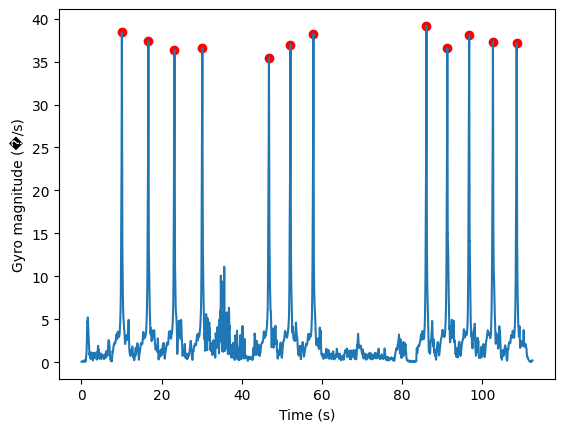

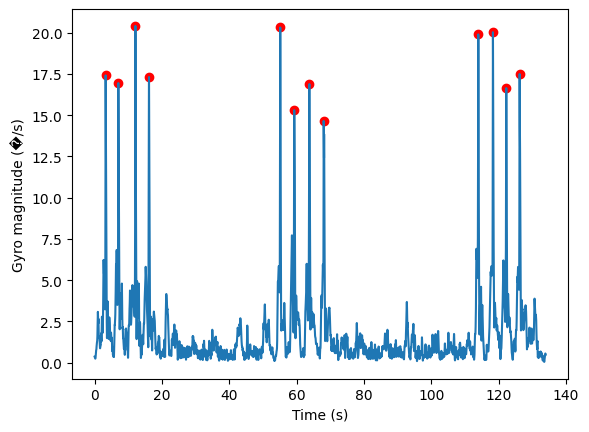

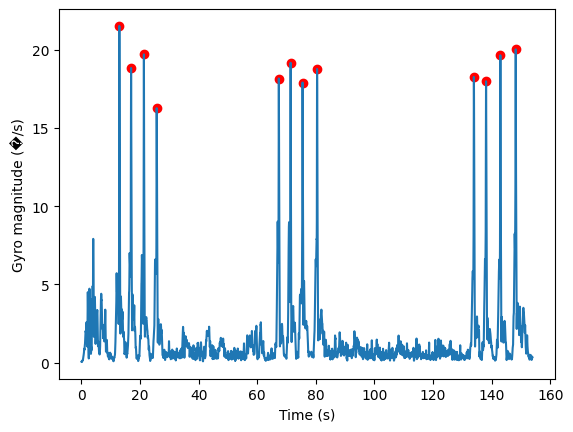

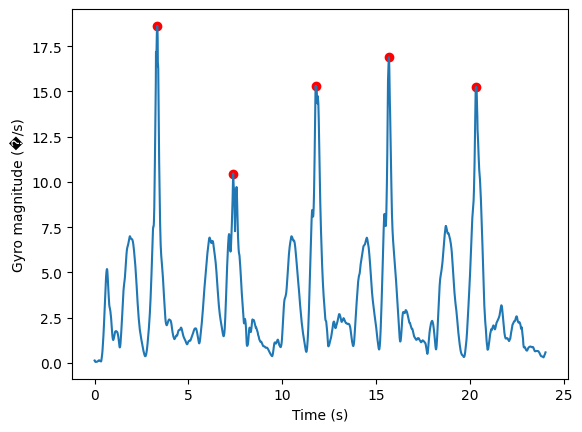

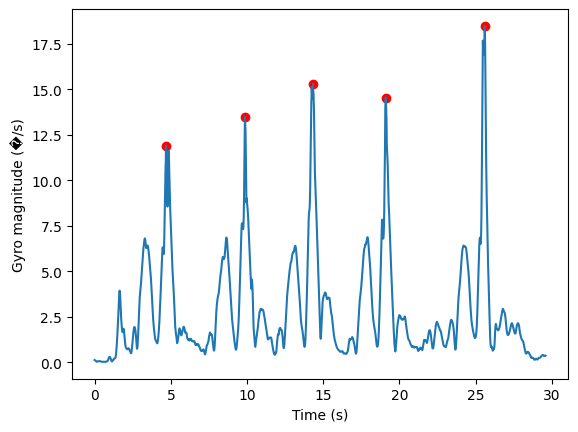

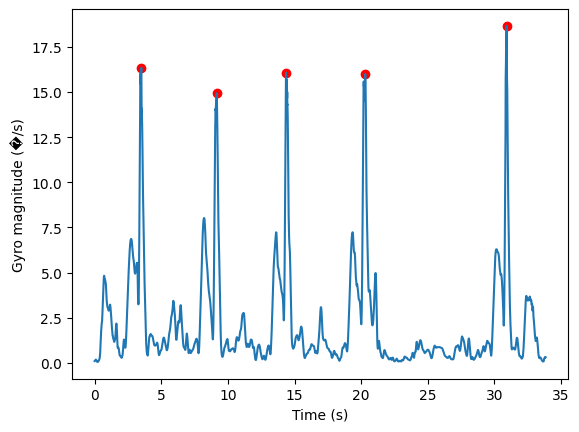

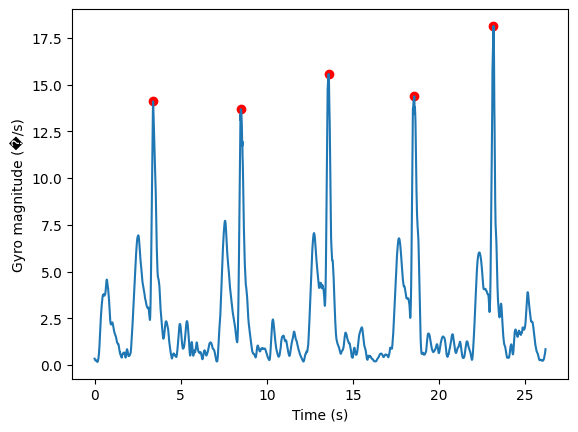

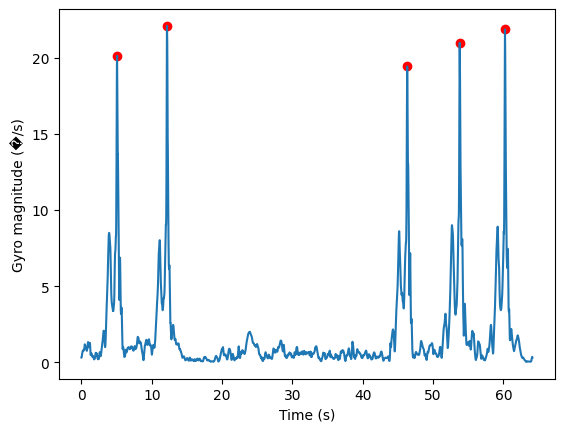

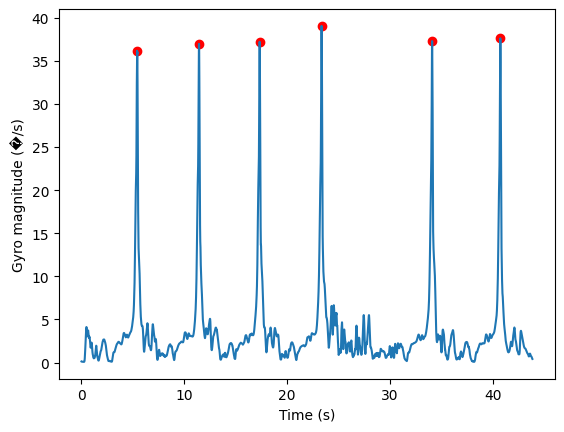

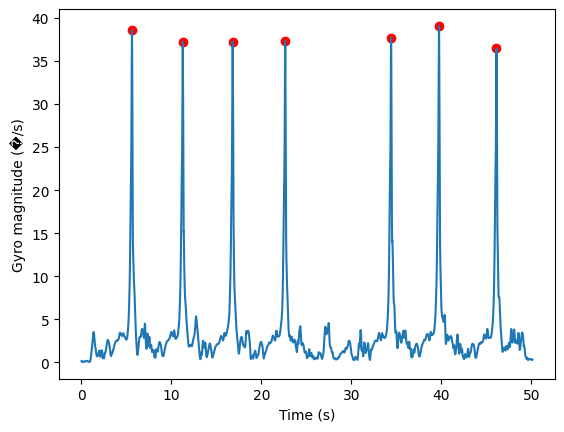

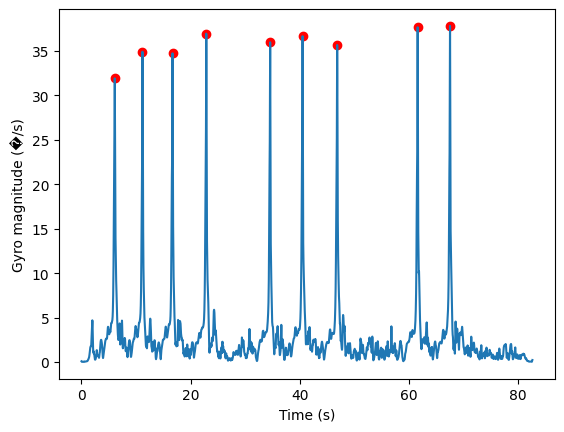

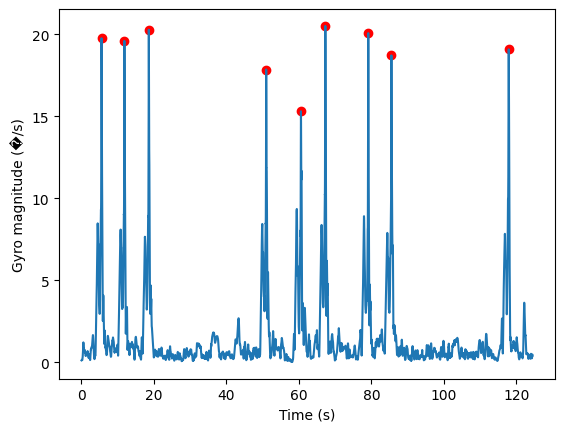

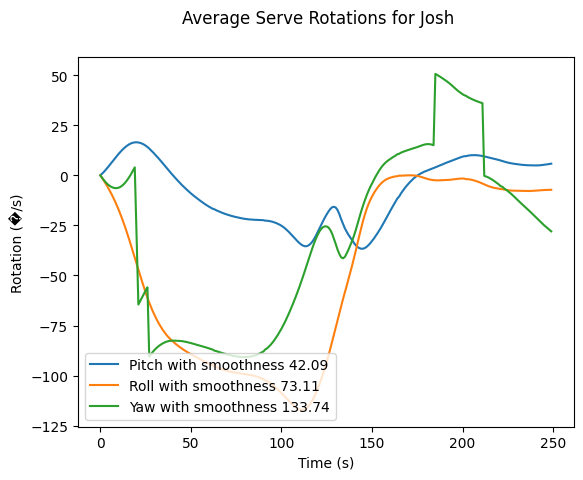

(250, 10)


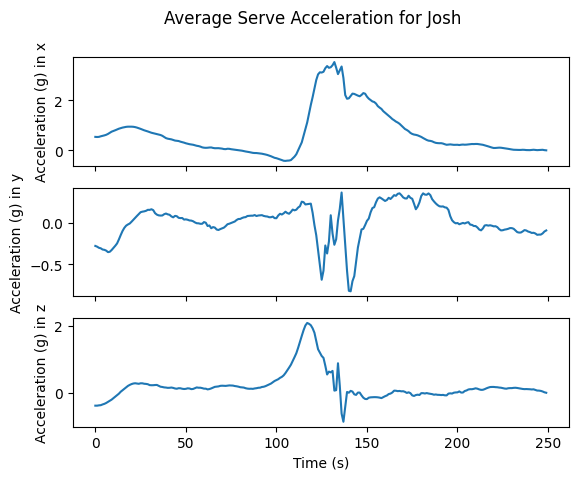

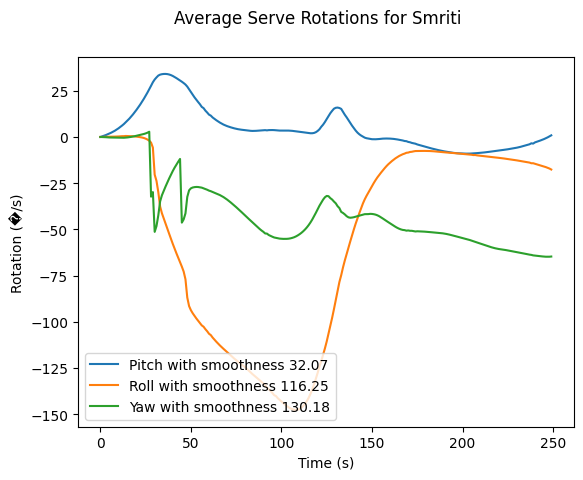

(250, 10)


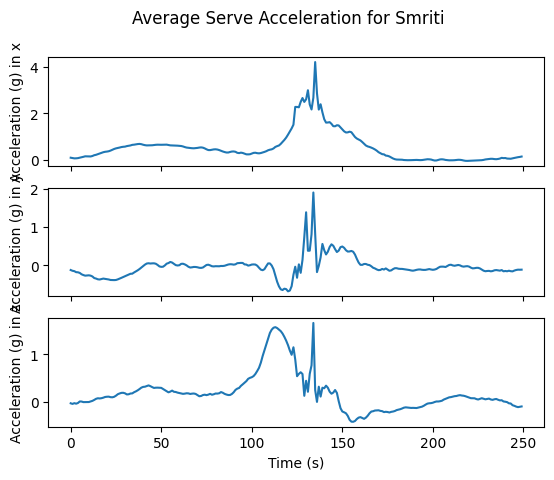

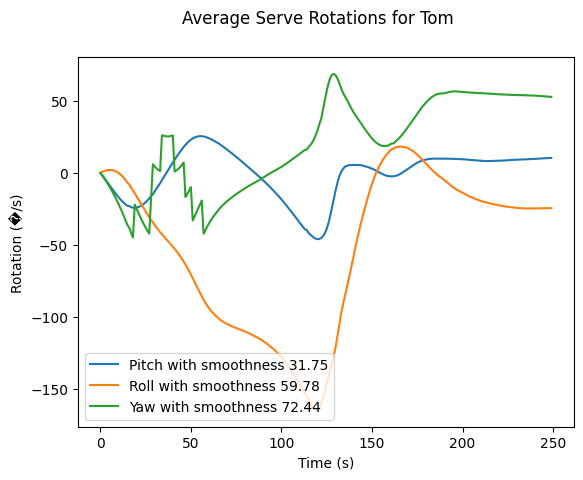

(250, 14)


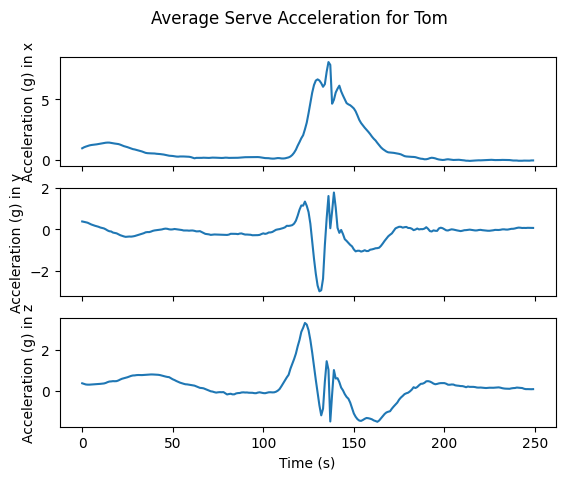

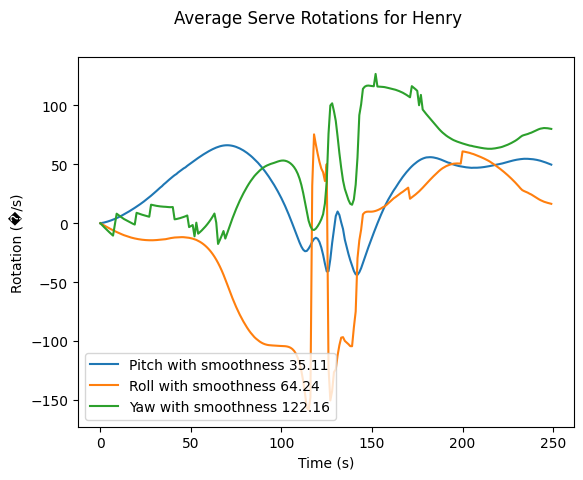

(250, 34)


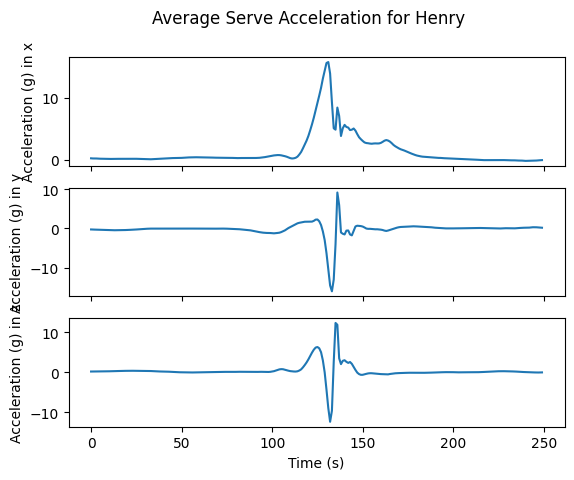

In [22]:
AllfGyroX, AllfGyroY, AllfGyroZ, AllfAccelX, AllfAccelY, AllfAccelZ,AllSignal_pitch, AllSignal_roll,AllSignal_yaw,Allfname,Allfshot,Allfshots_made = Compile(shot_filenames_list[4])
# AllfGyroX, AllfGyroY, AllfGyroZ, AllfAccelX, AllfAccelY, AllfAccelZ = cross_corr(AllfGyroX, AllfGyroY, AllfGyroZ, AllfAccelX, AllfAccelY, AllfAccelZ,128)
faMax, faMin, faMean, faStd, faArea, fgMax, fgMin, fgMean, fgStd, fgArea = MaxMin(AllfGyroX, AllfGyroY, AllfGyroZ, AllfAccelX, AllfAccelY, AllfAccelZ)
AllfGyro_av, AllfAccel_av, LinSpeeds, thetah_f, thetal_f, magAlow_f, magAhigh_f =feature_template(AllfGyroX, AllfGyroY, AllfGyroZ, AllfAccelX, AllfAccelY, AllfAccelZ,Allfname,AllSignal_pitch, AllSignal_roll,AllSignal_yaw,Allfshot)

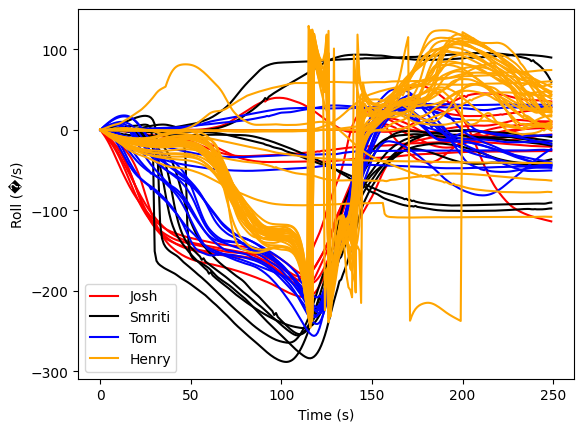

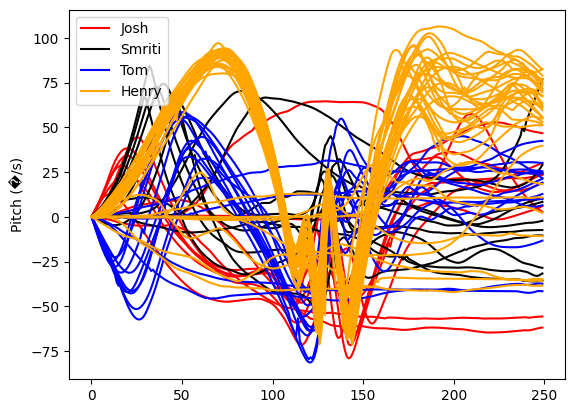

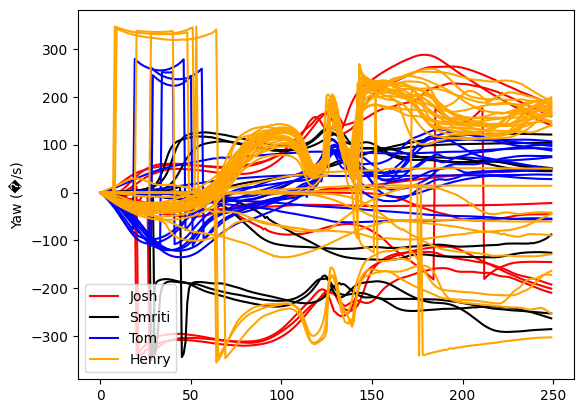

In [23]:
title= Allfname 
shot= Allfshot
#plot the individual shots for each player
colors= ['r','black','blue','orange','c','m','k','orange','purple']
# fig,axis= plt.subplots(3,1,sharex=True)
# fig.suptitle(f'Roll {np.unique(shot)[0]} for players')
plt.xlabel('Time (s)')


for i in players:
    plt.plot(AllSignal_roll[:,title==i],label= i, color= colors[players.index(i)])
plt.ylabel('Roll (�/s)')
handles, labels = plt.gca().get_legend_handles_labels()
by_label = dict(zip(labels, handles))
plt.legend(by_label.values(), by_label.keys())
plt.show()
for i in players:
    plt.plot(AllSignal_pitch[:,title==i],label= i, color= colors[players.index(i)])
plt.ylabel('Pitch (�/s)')
handles, labels = plt.gca().get_legend_handles_labels()
by_label = dict(zip(labels, handles))
plt.legend(by_label.values(), by_label.keys())
plt.show()
for i in players:
    plt.plot(AllSignal_yaw[:,title==i],label= i, color= colors[players.index(i)])
plt.ylabel('Yaw (�/s)')
handles, labels = plt.gca().get_legend_handles_labels()
by_label = dict(zip(labels, handles))
plt.legend(by_label.values(), by_label.keys())
plt.show()
# for i in players:
#     Signal_pitch= AllSignal_pitch[:,title==i]
    # if Signal_pitch.size > 0:
    #     fig2,ax2= plt.subplots(1,1)
    #     fig2.suptitle(f'Average {np.unique(shot)[0]} Rotations for '+ i)
    #     Signal_roll= AllSignal_roll[:,title==i]
    #     Signal_yaw= AllSignal_yaw[:,title==i]
    #     rotation_average= np.array([[np.average(Signal_pitch,axis=1)], [np.average(Signal_roll,axis=1)], [np.average(Signal_yaw,axis=1)]])
    #     pitch_smoothness= np.std(np.diff(Signal_pitch)).round(2)
    #     roll_smoothness= np.std(np.diff(Signal_roll)).round(2)
    #     yaw_smoothness= np.std(np.diff(Signal_yaw)).round(2)
    #     for j in range(rotation_average.shape[0]):
    #         ax2.plot(rotation_average[j,0,:]) 
    #         ax2.set_xlabel('Time (s)')
    #         ax2.set_ylabel('Rotation (�/s)')
    #     plt.legend([f'Pitch with smoothness {pitch_smoothness}', f'Roll with smoothness {roll_smoothness}', f'Yaw with smoothness {yaw_smoothness}'], loc='lower left')
    #     plt.show()
    #     Accelx= AllfAccelX[:,title==i]
    #     Accely= AllfAccelY[:,title==i]
    #     Accelz= AllfAccelZ[:,title==i]
    #     print(Accelx.shape)
    #     Accel=['x','y','z']
    #     fig,ax= plt.subplots(3,1,sharex=True)
    #     fig.suptitle(f'Average {np.unique(shot)[0]} Acceleration for '+ i)
    #     ax[2].set_xlabel('Time (s)')
    #     for j in range(3):
    #         ax[j].plot(np.average(eval(f'Accel{Accel[j]}'),axis=1))
    #         ax[j].set_ylabel('Acceleration (g) in ' + Accel[j])
    #     plt.show()